In [25]:
# Step 1: Ingest project ecosystem frameworks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import xgboost as xgb


In [26]:
# Step 2: Load the local NASA aerodynamic data array
local_csv = "airfoil_self_noise.csv"
df = pd.read_csv(local_csv)

# Defensive cleaning layer to strip any duplicates or empty instances
df = df.drop_duplicates().dropna()

print(f"Dataset Successfully Loaded! Matrix Shape: {df.shape[0]} rows, {df.shape[1]} columns.")
df.head()


Dataset Successfully Loaded! Matrix Shape: 1503 rows, 6 columns.


,f,alpha,c,U_infinity,delta,SSPL
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [27]:
# Step 3: Isolate target labels and scale input variables
X = df[["f", "alpha", "c", "U_infinity", "delta"]]
y = df["SSPL"]

# Standard 80/20 train/test random matrix division
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit and normalize physics vectors uniformly using standard Z-score scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data matrices split and input variance normalized successfully.")


Data matrices split and input variance normalized successfully.


In [28]:
# Step 4: Initialize and fit the Extreme Gradient Boosting Ensemble framework
model = xgb.XGBRegressor(n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42)
model.fit(X_train_scaled, y_train)

print("XGBoost Regressor training cycle complete.")


XGBoost Regressor training cycle complete.


In [29]:
# Step 5: Execute inference evaluation metrics
predictions = model.predict(X_test_scaled)

# Mathematical evaluation formulas
rmse = np.sqrt(mean_squared_error(y_test, predictions))
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("=== MODEL EVALUATION METRICS ===")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f} dB")
print(f"Mean Absolute Error (MAE):     {mae:.3f} dB")
print(f"Coefficient of Determination (R²): {r2*100:.2f}%")


=== MODEL EVALUATION METRICS ===
Root Mean Squared Error (RMSE): 1.835 dB
Mean Absolute Error (MAE):     1.239 dB
Coefficient of Determination (R²): 93.28%


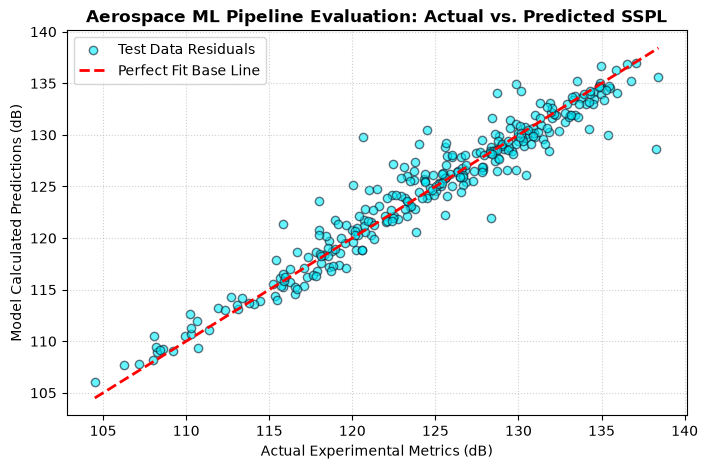

In [30]:
# Step 6: Generate an Actual vs. Predicted error scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(y_test, predictions, alpha=0.6, color='#00f0ff', edgecolors='#101526', label='Test Data Residuals')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Fit Base Line')

plt.title('Aerospace ML Pipeline Evaluation: Actual vs. Predicted SSPL', fontsize=12, fontweight='bold')
plt.xlabel('Actual Experimental Metrics (dB)', fontsize=10)
plt.ylabel('Model Calculated Predictions (dB)', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()
